In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv('data.fix.csv')
print(df)

      brand                                               name  price  \
0        HP                   Victus 15-fb0157AX Gaming Laptop  17465   
1        HP                                15s-fq5007TU Laptop  13965   
2      Acer                               One 14 Z8-415 Laptop   9447   
3    Lenovo               Yoga Slim 6 14IAP8 82WU0095IN Laptop  20905   
4     Apple                    MacBook Air 2020 MGND3HN Laptop  24497   
..      ...                                                ...    ...   
888    Asus          Vivobook 15X 2023 K3504VAB-NJ321WS Laptop  15746   
889    Asus                     TUF A15 FA577RM-HQ032WS Laptop  38500   
890    Asus  ROG Zephyrus G14 2023 GA402XV-N2034WS Gaming L...  66497   
891    Asus  TUF Gaming F15 2023 FX507VU-LP083WS Gaming Laptop  45497   
892    Asus  TUF Gaming A15 2023 FA577XU-LP041WS Gaming Laptop  46197   

     spec_rating                      processor  \
0      73.000000      5th Gen AMD Ryzen 5 5600H   
1      60.000000   12

# Cleaning & Preprocessing

In [2]:
import csv
#RAM
df['ram_gb'] = df['Ram'].str.extract(r'(\d+)', expand=False).astype(int)
#ROM
df['rom_gb'] = df['ROM'].str.extract(r'(\d+)',expand=False).astype(int)
#threads
t = df['CPU'].str.extract(r'(\d+)\s*Threads', expand=False).astype(float)
c = df['CPU'].str.extract(r'(\d+)\s*Cores?', expand=False).astype(float)
df['threads'] = t.fillna(c)
df = df.dropna(subset=['threads']).reset_index(drop=True)
df['threads'] = df['threads'].astype(int)
#การ์ดจอแยก
df['gpu_dedicated'] = df['GPU'].str.contains(
    'NVIDIA|GeForce|RTX|GTX|Radeon RX|Radeon Pro|Arc', case=False).astype(int)
df


,brand,name,price,spec_rating,processor,CPU,Ram,Ram_type,ROM,ROM_type,GPU,display_size,resolution_width,resolution_height,OS,warranty,ram_gb,rom_gb,threads,gpu_dedicated
0,HP,Victus 15-fb0157AX Gaming Laptop,17465,73.000000,5th Gen AMD Ryzen 5 5600H,"Hexa Core, 12 Threads",8GB,DDR4,512GB,SSD,4GB AMD Radeon RX 6500M,15.6,1920.0,1080.0,Windows 11 OS,1,8,512,12,1
1,HP,15s-fq5007TU Laptop,13965,60.000000,12th Gen Intel Core i3 1215U,"Hexa Core (2P + 4E), 8 Threads",8GB,DDR4,512GB,SSD,Intel UHD Graphics,15.6,1920.0,1080.0,Windows 11 OS,1,8,512,8,0
2,Acer,One 14 Z8-415 Laptop,9447,69.323529,11th Gen Intel Core i3 1115G4,"Dual Core, 4 Threads",8GB,DDR4,512GB,SSD,Intel Iris Xe Graphics,14.0,1920.0,1080.0,Windows 11 OS,1,8,512,4,0
3,Lenovo,Yoga Slim 6 14IAP8 82WU0095IN Laptop,20905,66.000000,12th Gen Intel Core i5 1240P,"12 Cores (4P + 8E), 16 Threads",16GB,LPDDR5,512GB,SSD,Intel Integrated Iris Xe,14.0,2240.0,1400.0,Windows 11 OS,1,16,512,16,0
4,Acer,Extensa EX214-53 Laptop,13997,62.000000,12th Gen Intel Core i5 1240P,"12 Cores (4P + 8E), 16 Threads",8GB,DDR4,512GB,SSD,Intel Iris Xe Graphics,14.0,1920.0,1080.0,Windows 11 OS,1,8,512,16,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
878,Asus,Vivobook 15X 2023 K3504VAB-NJ321WS Laptop,15746,69.323529,13th Gen ‎Intel Core i3 1315U,"Hexa Core (2P + 4E), 8 Threads",8GB,DDR4,512GB,SSD,Integrated Intel UHD Graphics,15.6,1920.0,1080.0,Windows 11 OS,1,8,512,8,0
879,Asus,TUF A15 FA577RM-HQ032WS Laptop,38500,71.000000,6th Gen AMD Ryzen 7 6800H,"Octa Core, 16 Threads",16GB,DDR,1TB,SSD,6GB NVIDIA GeForce RTX 3060,15.6,2560.0,1440.0,Windows 11 OS,1,16,1,16,1
880,Asus,ROG Zephyrus G14 2023 GA402XV-N2034WS Gaming L...,66497,89.000000,7th Gen AMD Ryzen 9 7940HS,"Octa Core, 16 Threads",32GB,DDR5,1TB,SSD,8GB NVIDIA GeForce RTX 4060,14.0,2560.0,1600.0,Windows 11 OS,1,32,1,16,1
881,Asus,TUF Gaming F15 2023 FX507VU-LP083WS Gaming Laptop,45497,73.000000,13th Gen Intel Core i7 13700H,"14 Cores (6P + 8E), 20 Threads",16GB,DDR4,512GB,SSD,6GB NVIDIA GeForce RTX 4050,15.6,1920.0,1080.0,Windows 11 OS,1,16,512,20,1


Feature & Scale

In [23]:
features = ['gpu_dedicated','display_size','ram_gb','threads']

print(df[features + ['resolution_height','price']].corr().round(2))

#Scale
from sklearn.preprocessing import StandardScaler

print(df[features].std().round(2))

scaler = StandardScaler() 
X = scaler.fit_transform(df[features])

print(X.mean(axis=0),round(2))
print(X.std(axis=0),round(2))

                   gpu_dedicated  display_size  ram_gb  threads  \
gpu_dedicated               1.00          0.46    0.34     0.50   
display_size                0.46          1.00    0.17     0.28   
ram_gb                      0.34          0.17    1.00     0.65   
threads                     0.50          0.28    0.65     1.00   
resolution_height           0.11          0.04    0.44     0.45   
price                       0.41          0.24    0.74     0.71   

                   resolution_height  price  
gpu_dedicated                   0.11   0.41  
display_size                    0.04   0.24  
ram_gb                          0.44   0.74  
threads                         0.45   0.71  
resolution_height               1.00   0.60  
price                           0.60   1.00  
gpu_dedicated    0.48
display_size     0.92
ram_gb           6.45
threads          5.39
dtype: float64
[8.85160826e-17 1.95137728e-15 1.44844499e-16 1.44844499e-16] 2
[1. 1. 1. 1.] 2


หา K

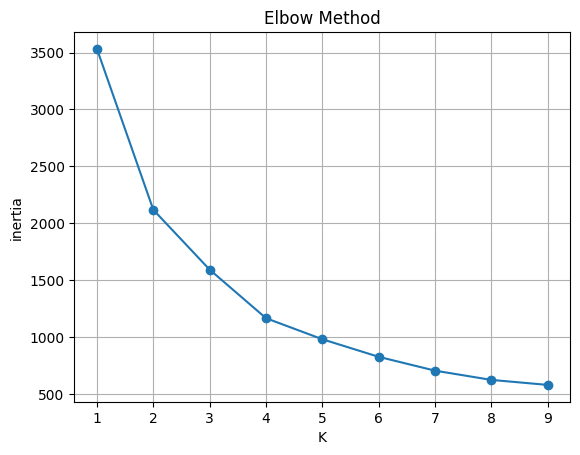

   k  inertia  Decrease from previous K
0  1   3532.0                       NaN
1  2   2118.0                    1414.0
2  3   1591.0                     526.0
3  4   1164.0                     427.0
4  5    979.0                     185.0
5  6    825.0                     155.0
6  7    703.0                     122.0
7  8    622.0                      81.0
8  9    578.0                      44.0


In [4]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

ks = range(1, 10)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_ for k in ks]

plt.plot(ks, inertia, 'o-')
plt.xlabel('K'); plt.ylabel('inertia'); plt.title('Elbow Method')
plt.xticks(ks); plt.grid(True); plt.show()

print(pd.DataFrame({'k': ks, 'inertia': inertia,
                    'Decrease from previous K': pd.Series(inertia).diff().abs()}).round(0))

PCA Elbow

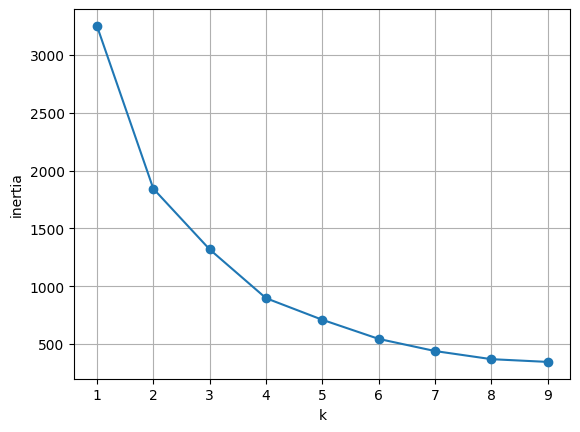

In [5]:
from sklearn.decomposition import PCA

Z = PCA(n_components=3).fit_transform(X)  

inertia = [KMeans(k, n_init=10, random_state=42).fit(Z).inertia_ for k in range(1, 10)]
plt.plot(range(1, 10), inertia, 'o-'); plt.xlabel('k'); plt.ylabel('inertia'); plt.grid();plt.show()

K = 3

In [65]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
df['cluster'] = km.fit_predict(X)

print(df['cluster'].value_counts().sort_index())      # จำนวนเครื่องในแต่ละกลุ่ม

# ศูนย์กลางของแต่ละกลุ่ม แปลงกลับเป็นหน่วยเดิม
centers = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=features).round(1)
centers['n'] = df['cluster'].value_counts().sort_index().values
print(centers)

order = df.groupby('cluster')['ram_gb'].median().sort_values().index
df['cluster'] = df['cluster'].map({old: new for new, old in enumerate(order)})

summary = df.groupby('cluster').agg(
    จำนวนเครื่อง=('cluster', 'count'),
    GPU_แยก=('gpu_dedicated', 'mean'),
    ขนาดหน้าจอ=('display_size', 'mean'),
    RAM_GB=('ram_gb', 'mean'),
    Threads=('threads', 'mean'),
    Spec_rating=('spec_rating','mean')
).round(1)


summary = summary.sort_values('RAM_GB', ascending=True)

display(summary)

cluster
0    320
1    250
2    313
Name: count, dtype: int64
   gpu_dedicated  display_size  ram_gb  threads    n
0            1.0          15.8    16.4     15.9  320
1            0.0          13.9    12.6     10.7  250
2            0.0          15.6    10.7      9.6  313


,จํานวนเครื่อง,GPU_แยก,ขนาดหน้าจอ,RAM_GB,Threads,Spec_rating
cluster,,,,,,
0,313,0.0,15.6,10.7,9.6,67.5
2,250,0.0,13.9,12.6,10.7,67.3
1,320,1.0,15.8,16.4,15.9,72.8


K = 4

In [67]:
km = KMeans(n_clusters=4, n_init=10, random_state=42)
df['cluster'] = km.fit_predict(X)

print(df['cluster'].value_counts().sort_index())      # จำนวนเครื่องในแต่ละกลุ่ม

# ศูนย์กลางของแต่ละกลุ่ม แปลงกลับเป็นหน่วยเดิม
centers = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=features).round(1)
centers['n'] = df['cluster'].value_counts().sort_index().values
print(centers)

order = df.groupby('cluster')['ram_gb'].median().sort_values().index
df['cluster'] = df['cluster'].map({old: new for new, old in enumerate(order)})

summary = df.groupby('cluster').agg(
    จำนวนเครื่อง=('cluster', 'count'),
    GPU_แยก=('gpu_dedicated', 'mean'),
    ขนาดหน้าจอ=('display_size', 'mean'),
    RAM_GB=('ram_gb', 'mean'),
    Threads=('threads', 'mean'),
    Spec_rating=('spec_rating','mean')
).round(1)

display(summary)

cluster
0    250
1    277
2    312
3     44
Name: count, dtype: int64
   gpu_dedicated  display_size  ram_gb  threads    n
0            0.0          13.9    12.6     10.7  250
1            1.0          15.7    13.9     14.6  277
2            0.0          15.6    10.6      9.6  312
3            0.9          16.0    32.4     23.7   44


,จํานวนเครื่อง,GPU_แยก,ขนาดหน้าจอ,RAM_GB,Threads,Spec_rating
cluster,,,,,,
0,312,0.0,15.6,10.6,9.6,67.5
1,250,0.0,13.9,12.6,10.7,67.3
2,277,1.0,15.7,13.9,14.6,71.7
3,44,0.9,16.0,32.4,23.7,79.3


# กราฟกุมั่ว

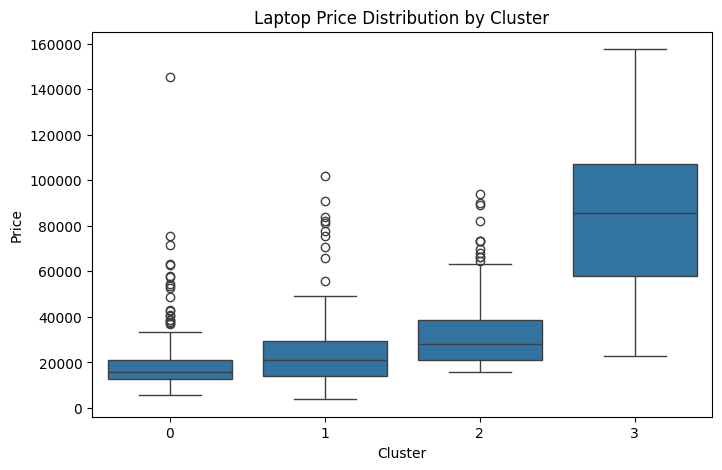

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='cluster', y='price')

plt.title('Laptop Price Distribution by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Price')
plt.show()

# กราฟแท่งเทียบ RAM กับ Threads ของแต่ละกลุ่ม
* อาจต้องดูดีๆว่ากลุ่มที่ plot มาตรงกับตารางกลุ่ม cluster ของ kmeans มั้ย

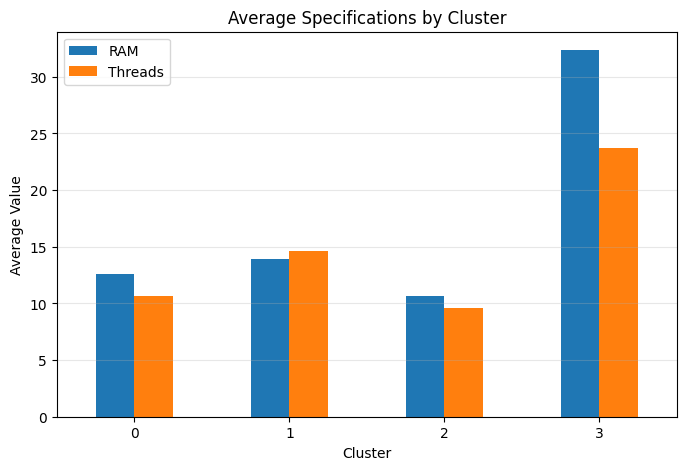

In [60]:
profile = df.groupby('cluster').agg(
    RAM=('ram_gb', 'mean'),
    Threads=('threads', 'mean')
)

profile.plot(kind='bar', figsize=(8, 5))

plt.title('Average Specifications by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

# กราฟ KMEANS Clustering เทียบ ram กับ threads

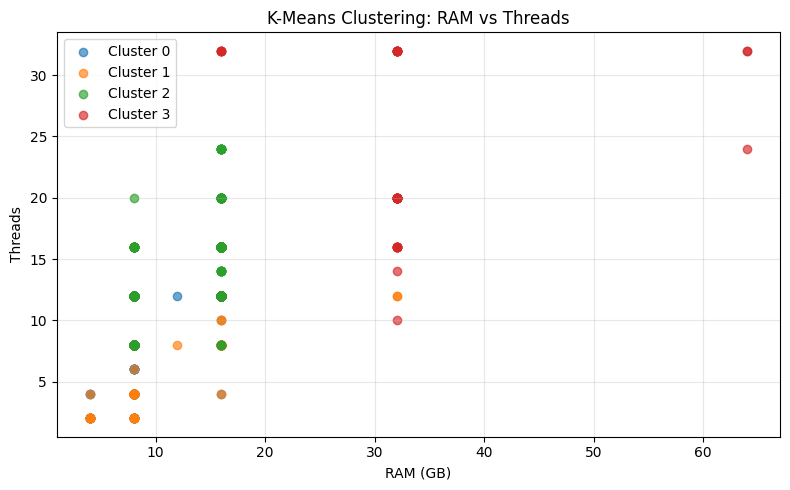

In [51]:
plt.figure(figsize=(8, 5))

for c in sorted(df['cluster'].dropna().unique()):
    data = df[df['cluster'] == c]
    plt.scatter(
        data['ram_gb'],
        data['threads'],
        label=f'Cluster {c}',
        alpha=0.65
    )

plt.xlabel('RAM (GB)')
plt.ylabel('Threads')
plt.title('K-Means Clustering: RAM vs Threads')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# กราฟเทียบแต่ละกลุ่ม
* อาจต้องดูดีๆว่ากลุ่มที่ plot มาตรงกับตารางกลุ่ม cluster ของ kmeans มั้ย

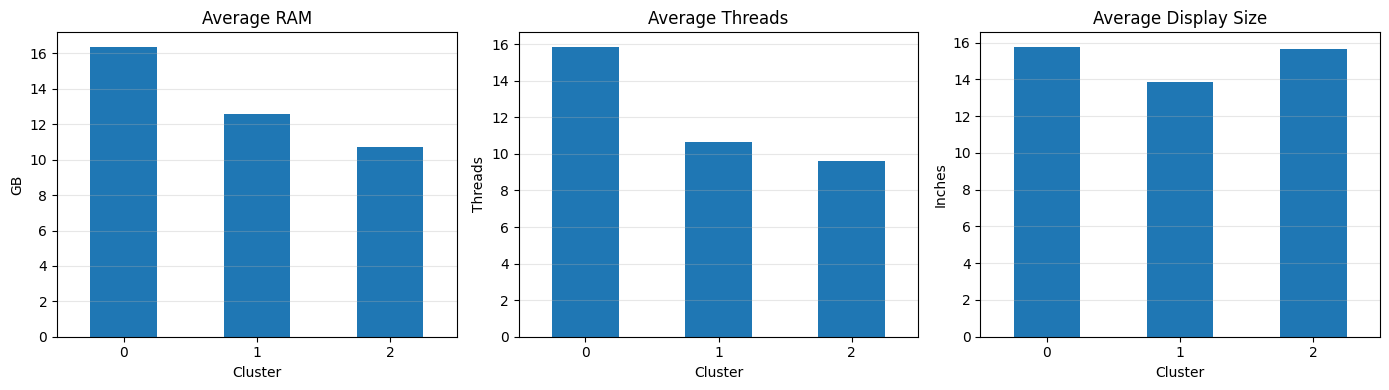

In [56]:
from sklearn.cluster import KMeans

k = 3  # เปลี่ยนค่า K ได้ตรงนี้

km = KMeans(n_clusters=k, n_init=10, random_state=42)
df['cluster'] = km.fit_predict(X_scaled)

profile = df.groupby('cluster').agg(
    RAM=('ram_gb', 'mean'),
    Threads=('threads', 'mean'),
    ขนาดจอ=('display_size', 'mean')
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

profile['RAM'].plot(kind='bar', ax=axes[0])
axes[0].set_title('Average RAM')
axes[0].set_ylabel('GB')

profile['Threads'].plot(kind='bar', ax=axes[1])
axes[1].set_title('Average Threads')
axes[1].set_ylabel('Threads')

profile['ขนาดจอ'].plot(kind='bar', ax=axes[2])
axes[2].set_title('Average Display Size')
axes[2].set_ylabel('Inches')

for ax in axes:
    ax.set_xlabel('Cluster')
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

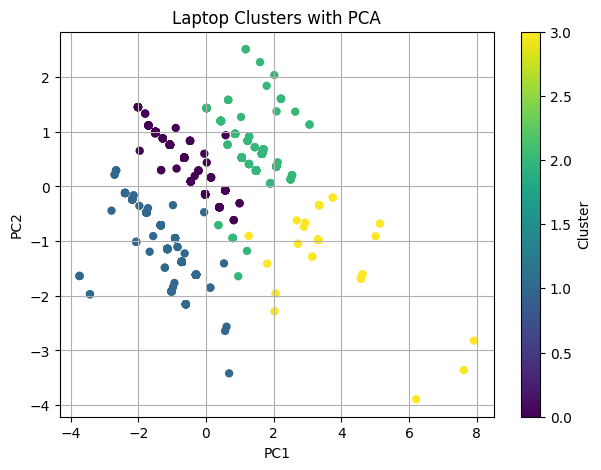

Variance explained: 79.62 %


In [48]:

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(7, 5))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=df['cluster'], cmap='viridis', s=25
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Laptop Clusters with PCA')
plt.colorbar(label='Cluster')
plt.grid()
plt.show()

print('Variance explained:',
      round(pca.explained_variance_ratio_.sum() * 100, 2), '%')


# K-Medoids ไม่ได้ใช้


In [12]:

import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances, silhouette_score

# คำนวณระยะห่างระหว่างข้อมูลทุกคู่
D = pairwise_distances(X, metric='euclidean')

# กำหนดจำนวนกลุ่ม
k = 3
np.random.seed(42)

# สุ่มเลือกจุดเริ่มต้น k จุดจากข้อมูลจริง
medoids = np.random.choice(len(X), k, replace=False)

# ทำ K-Medoids
for _ in range(100):
    # จัดข้อมูลเข้ากลุ่มตาม Medoid ที่ใกล้ที่สุด
    labels = D[:, medoids].argmin(axis=1)

    new_medoids = medoids.copy()

    # หา Medoid ใหม่ของแต่ละกลุ่ม
    for i in range(k):
        members = np.where(labels == i)[0]

        if len(members) > 0:
            distances = D[np.ix_(members, members)]
            new_medoids[i] = members[
                distances.sum(axis=1).argmin()
            ]

    # หยุดเมื่อ Medoid ไม่เปลี่ยน
    if np.array_equal(medoids, new_medoids):
        break

    medoids = new_medoids

# จัดกลุ่มครั้งสุดท้าย
labels = D[:, medoids].argmin(axis=1)
df['cluster_medoid'] = labels

# แสดงจำนวนข้อมูลในแต่ละกลุ่ม
print(df['cluster_medoid'].value_counts().sort_index())

# ประเมินคุณภาพการจัดกลุ่ม
print("Silhouette Score:",
      round(silhouette_score(D, labels, metric='precomputed'), 3))

# แสดงข้อมูลตัวแทนของแต่ละกลุ่ม
print("\nMedoid ของแต่ละกลุ่ม:")
print(df.iloc[medoids][features])


cluster_medoid
0    315
1    324
2    244
Name: count, dtype: int64
Silhouette Score: 0.402

Medoid ของแต่ละกลุ่ม:
    gpu_dedicated  display_size  ram_gb  threads
1               0          15.6       8        8
11              1          15.6      16       16
34              0          14.0      16       12


In [13]:

from sklearn.metrics import silhouette_score

score_kmeans = silhouette_score(X, df['cluster'])
score_kmedoids = silhouette_score(X, df['cluster_medoid'])

print("K-Means:", round(score_kmeans, 3))
print("K-Medoids:", round(score_kmedoids, 3))


K-Means: 0.473
K-Medoids: 0.402


# แบ่งกลุ่มด้วย Hierachical Clustering

In [14]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

df = pd.read_csv("cleandata.csv")

features = ['ram_gb', 'gpu_dedicated', 'display_size', 'threads']

# เลือกแถวที่มีข้อมูลครบ
X = df[features].dropna().copy()

# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Hierarchical Clustering
linked = linkage(X_scaled, method='ward')

# แบ่งเป็น 4 กลุ่ม
n_clusters = 4
clusters = fcluster(linked, t=n_clusters, criterion='maxclust')

X['cluster_hc'] = clusters - 1

# แสดงจำนวนสมาชิก
print(X['cluster_hc'].value_counts().sort_index())

# แสดงค่าเฉลี่ยของแต่ละกลุ่ม
print(X.groupby('cluster_hc')[features].mean().round(1))

# แสดงตัวอย่างข้อมูล
for i in range(n_clusters):
    print(f"\n=== Cluster {i} ===")
    print(X[X['cluster_hc'] == i][features].head())


cluster_hc
0     42
1    285
2    244
3    312
Name: count, dtype: int64
            ram_gb  gpu_dedicated  display_size  threads
cluster_hc                                              
0             34.3            0.8          15.9     22.0
1             13.9            1.0          15.7     14.8
2             12.3            0.0          13.9     10.6
3             10.6            0.0          15.6      9.6

=== Cluster 0 ===
     ram_gb  gpu_dedicated  display_size  threads
15       32              0          15.6       20
42       32              1          16.0       32
58       32              1          16.0       20
106      32              1          15.6       16
136      32              1          16.0       20

=== Cluster 1 ===
    ram_gb  gpu_dedicated  display_size  threads
0        8              1          15.6       12
6       16              1          15.6       12
11      16              1          15.6       16
13       8              1          15.6       12
16

* เทียบค่าความใกล้เคียงของ kmeans และ hierachical

In [15]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# K-Means: ใช้ข้อมูลที่ผ่าน Scaling แล้ว
km = KMeans(n_clusters=4, n_init=10, random_state=42)
labels_km = km.fit_predict(X_scaled)

# Hierarchical: ใช้ผลที่สร้างไว้แล้วใน X
labels_hc = X['cluster_hc'].to_numpy()

# เปรียบเทียบผลการแบ่งกลุ่ม
ari = adjusted_rand_score(labels_km, labels_hc)

print("ARI Score:", round(ari, 3))


ARI Score: 0.976


In [16]:
from sklearn.metrics import silhouette_score

print("K-Means:",
      round(silhouette_score(X_scaled, labels_km), 3))

print("Hierarchical:",
      round(silhouette_score(X_scaled, labels_hc), 3))

K-Means: 0.473
Hierarchical: 0.47


# กราฟ Dendrogram แบบ PCA และ ไม่ PCA

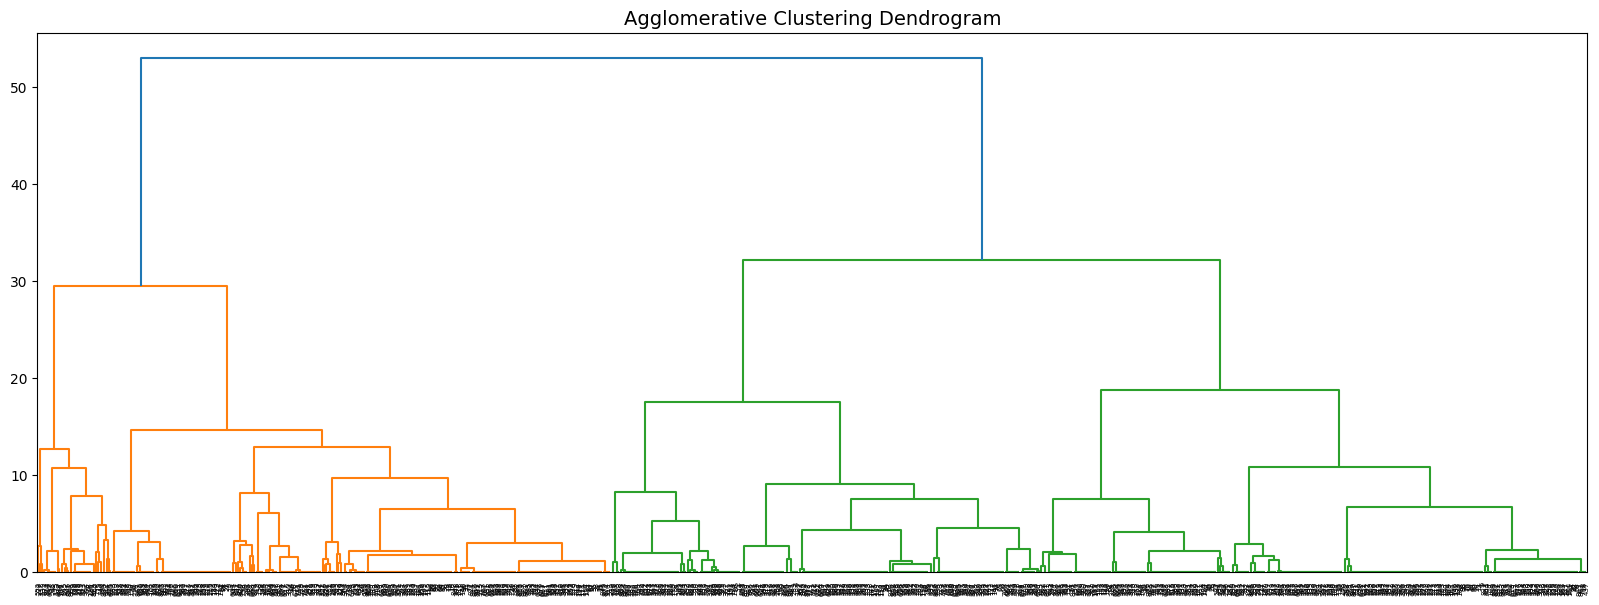

จำนวนตัวแปรเดิม: 4
จำนวนตัวแปรหลัง PCA: 4
Explained Variance: 1.0


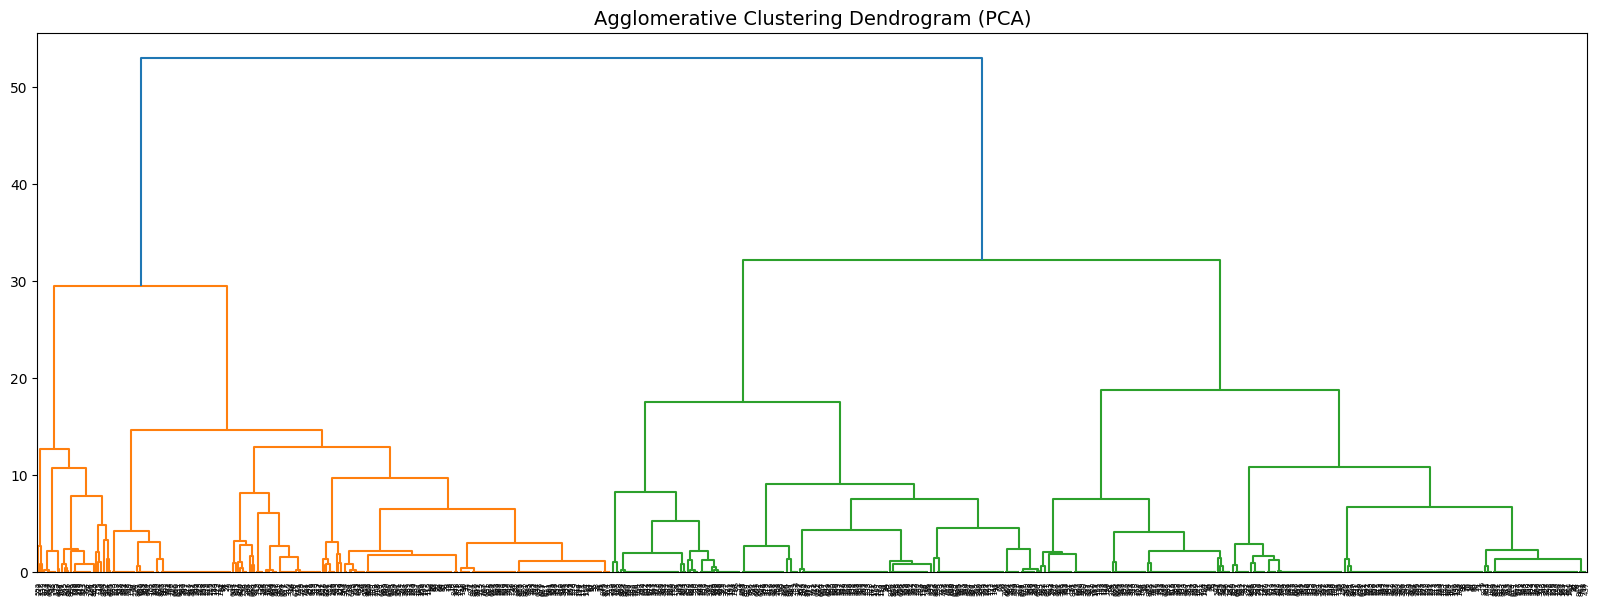

In [17]:

#ทำpcaและไม่ทำ pca
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
 
df = pd.read_csv("cleandata.csv")
 
# เลือกตัวแปรที่ใช้
features = ['ram_gb','gpu_dedicated','display_size','threads']
X = df[features].dropna()
 
# ปรับสเกลข้อมูล
X_scaled = StandardScaler().fit_transform(X)
 
# -------------------------------
# 1. Dendrogram (ไม่ทำ PCA)
# -------------------------------
plt.figure(figsize=(20, 7))
plt.title("Agglomerative Clustering Dendrogram", fontsize=14)
dendrogram(linkage(X_scaled, method='ward'))
plt.show()
 
# -------------------------------
# 2. ทำ PCA
# -------------------------------
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)
 
print("จำนวนตัวแปรเดิม:", X_scaled.shape[1])
print("จำนวนตัวแปรหลัง PCA:", X_pca.shape[1])
print("Explained Variance:",
      round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(20, 7))
plt.title("Agglomerative Clustering Dendrogram (PCA)", fontsize=14)
dendrogram(linkage(X_pca, method='ward'))
plt.show()
 
 
 

# KMEAN_PCA

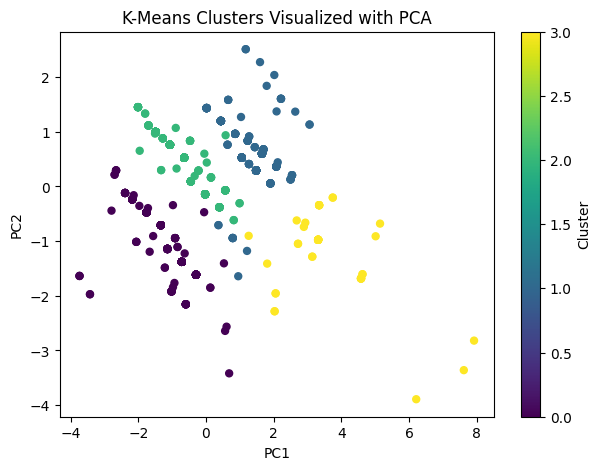

Explained variance: 79.62 %


In [18]:

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 1. จัดกลุ่มด้วย Features ที่ผ่าน Scaling แล้ว
km = KMeans(n_clusters=4, n_init=10, random_state=42)
labels = km.fit_predict(X_scaled)

# 2. ลดมิติสำหรับแสดงกราฟเท่านั้น
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 3. แสดง Cluster เดิมบนกราฟ PCA
plt.figure(figsize=(7, 5))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels, cmap='viridis', s=25
)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-Means Clusters Visualized with PCA')
plt.colorbar(label='Cluster')
plt.show()

print("Explained variance:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


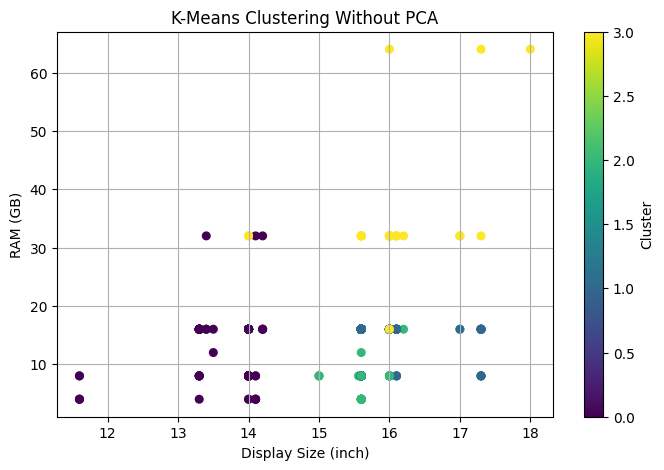

In [19]:

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# กำหนดจำนวนกลุ่ม
k = 4

# จัดกลุ่มด้วยข้อมูลที่ผ่าน Scaling แล้ว
km = KMeans(n_clusters=k, n_init=10, random_state=42)
df['cluster'] = km.fit_predict(X_scaled)

# แสดงกราฟโดยใช้ Features จริง 2 ตัว
plt.figure(figsize=(8, 5))

plt.scatter(
    X['display_size'],
    X['ram_gb'],
    c=df.loc[X.index, 'cluster'],
    cmap='viridis',
    s=30
)

plt.xlabel('Display Size (inch)')
plt.ylabel('RAM (GB)')
plt.title('K-Means Clustering Without PCA')
plt.colorbar(label='Cluster')
plt.grid()
plt.show()
